In [ ]:
# --- 1. Manipulation du système de fichiers ---
import os   # Permet d'explorer les dossiers, créer des chemins et gérer les fichiers sur le disque
import glob  # Permet de rechercher des fichiers correspondant à un motif spécifique (ex: *.jpg)
import time  # Permet de calculer le temps d'exécution de l'entraînement et des opérations

# --- 2. Traitement et manipulation d'images ---
import cv2  # OpenCV : Bibliothèque principale pour charger, redimensionner et transformer les images IRM
from PIL import Image  # Pillow : Alternative à OpenCV pour ouvrir et vérifier la validité des fichiers images

# --- 3. Calcul numérique et gestion des données ---
import numpy as np  # Permet de manipuler les images sous forme de tableaux multidimensionnels (matrices de pixels)
import pandas as pd  # Permet de structurer et d'analyser les données (pratique pour résumer le dataset)

# --- 4. Visualisation des données ---
import matplotlib.pyplot as plt  # Permet d'afficher les images IRM et de tracer les courbes d'apprentissage (Loss/Accuracy)
import seaborn as sns  # Améliore le rendu visuel des graphiques (notamment pour la matrice de confusion)

# --- 5. Utilitaires de préparation des données et évaluation ---
import random  # Permet de mélanger aléatoirement les listes d'images
from sklearn.utils import shuffle  # Permet de mélanger de manière synchronisée les images et leurs étiquettes (labels)
from sklearn.preprocessing import LabelEncoder  # Permet de convertir les noms des classes textuelles en valeurs numériques
from sklearn.model_selection import train_test_split  # Permet de séparer les données en jeux d'entraînement et de validation
from sklearn.metrics import classification_report, confusion_matrix  # Permet de calculer les métriques d'évaluation (Précision, Rappel, F1-Score)

# --- 6. Deep Learning avec TensorFlow & Keras ---
from tensorflow.keras.utils import to_categorical, plot_model  # Convertit les étiquettes en encodage one-hot et permet de visualiser le modèle
from tensorflow.keras.models import Sequential, load_model  # Modèle séquentiel couche par couche et fonction de rechargement des modèles sauvegardés
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout  # Couches fondamentales du réseau de neurones CNN
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom  # Couches dynamiques pour l'augmentation de données (Data Augmentation)
from tensorflow.keras.optimizers import Adam  # Optimiseur pour l'ajustement des poids du réseau
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping  # Callback pour sauvegarder automatiquement le meilleur modèle pendant l'entraînement

In [5]:
# 1. On définit le chemin vers le dossier principal des images
dossier_dataset = "../Data"

# Listes pour stocker les images valides et leurs classes (labels)
images_valides = []
labels = []

# 2. Liste des extensions d'images autorisées
extensions_valides = [".jpg", ".jpeg", ".png", ".bmp"]

# Compteurs pour savoir ce qu'on fait
fichiers_gardes = 0
fichiers_supprimes = 0

# 3. On parcourt tous les dossiers et fichiers du dataset
for racine, dosssiers, fichiers in os.walk(dossier_dataset):
    for fichier in fichiers:
        chemin_fichier = os.path.join(racine, fichier)
        extension = os.path.splitext(fichier)[1].lower()

        # 1. Vérification de l'extension
        if extension in extensions_valides:
            # 2. Vérification que l'image n'est pas corrompue
            try:
                with Image.open(chemin_fichier) as img:
                    img.verify() # S'assure que le fichier image est lisible

                # Si tout est OK, on sauvegarde le chemin et le nom du dossier (la classe)
                images_valides.append(chemin_fichier)
                labels.append(os.path.basename(racine))
                fichiers_gardes += 1

            except Exception:
                # Si l'extension n'est pas bonne, on la supprime
                os.remove(chemin_fichier)
                fichiers_supprimes += 1

print("--- Bilan du nettoyage et du chargement ---")
print(f"Images valides conservées : {fichiers_gardes}")
print(f"Fichiers corrompus/invalides supprimés : {fichiers_supprimes}")


--- Bilan du nettoyage et du chargement ---
Images valides conservées : 7023
Fichiers corrompus/invalides supprimés : 0


In [6]:
# --- 1. Exploration des classes ---
# On utilise pandas pour compter facilement le nombre d'images par classe
df_classes = pd.DataFrame({"label": labels})

print("--- Nombre d'images par classe ---")
print(df_classes['label'].value_counts())
print(df_classes.count())

# --- 2. Mélange synchronisé des images et des labels ---
# shuffle() mélange les 2 listes en gardant exactement le même ordre d'indices !
images_valides, labels = shuffle(images_valides, labels, random_state=42)

# --- 3. Vérification rapide du lien entre image et label ---
print("\n--- Test d'indexation (vérification du même indice) ---")
print(f"Première image (indice 0) : {images_valides[0]}")
print(f"Son label associé (indice 0) : {labels[0]}")



--- Nombre d'images par classe ---
label
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64
label    7023
dtype: int64

--- Test d'indexation (vérification du même indice) ---
Première image (indice 0) : ../Data\notumor\Tr-no_0239.jpg
Son label associé (indice 0) : notumor


In [10]:
# 1. On fixe la taille souhaitée pour les images
taille_image = (224, 224)

# Liste pour stocker les matrices de pixels des images
X_data = []

# 2. Boucle pour charger et redimensionner chaque image
for chemin in images_valides:
    # Charger l'image depuis son chemin avec OpenCV
    img = cv2.imread(chemin)

    # OpenCV lit les images en BGR par défaut, on les convertit en RGB (couleurs réelles)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Redimensionner l'image à 224x224
    img_redimensionnee = cv2.resize(img, taille_image)

    X_data.append(img_redimensionnee)

# 3. Conversion des listes en tableaux NumPy
X = np.array(X_data)
y = np.array(labels)

# 4. Vérification des dimensions des tableaux
print("--- Vérification des dimensions ---")
print(f"Forme du tableau d'images (X) : {X.shape}")
print(f"Forme du tableau d'étiquettes (y) : {y.shape}")


--- Vérification des dimensions ---
Forme du tableau d'images (X) : (7023, 224, 224, 3)
Forme du tableau d'étiquettes (y) : (7023,)


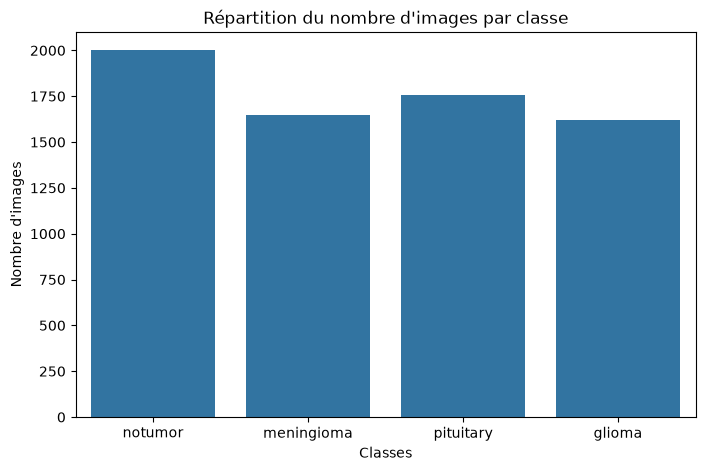

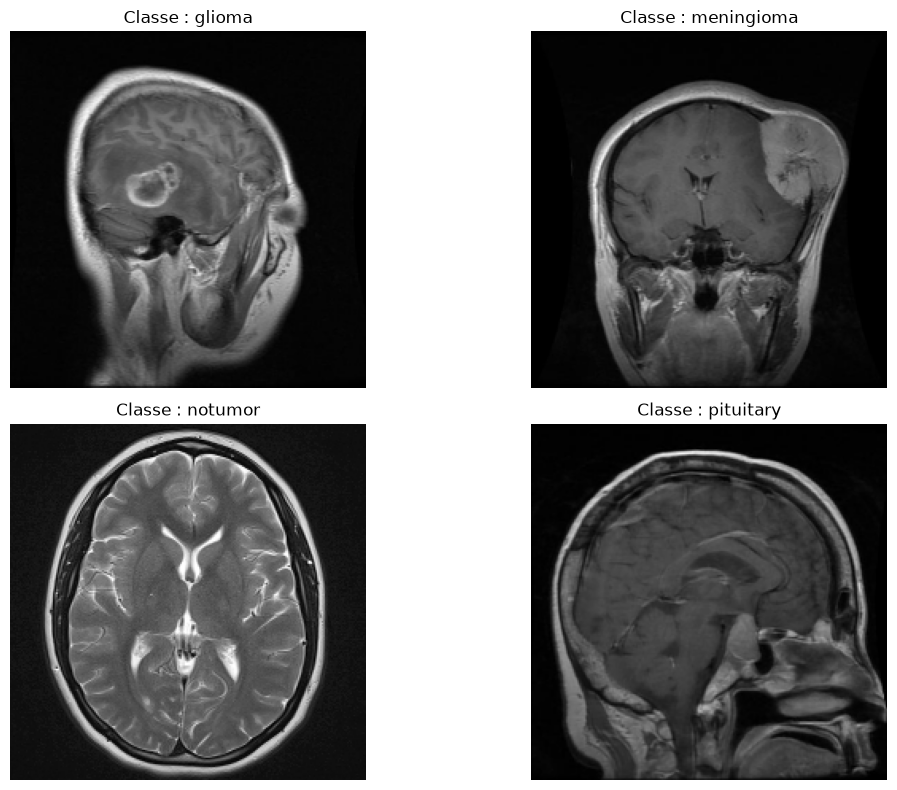

In [11]:
# --- 1. Graphique du nombre d'images par classe ---
plt.figure(figsize=(8, 5))
sns.countplot(x=y)
plt.title("Répartition du nombre d'images par classe")
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
plt.show()

# --- 2. Affichage d'un échantillon d'images pour chaque classe ---
classes_uniques = np.unique(y)

plt.figure(figsize=(12, 8))
for i, classe in enumerate(classes_uniques):
    # Trouver le premier indice où cette classe apparaît
    indice = np.where(y == classe)[0][0]
    
    # Afficher l'image dans une grille
    plt.subplot(2, 2, i + 1)
    plt.imshow(X[indice])
    plt.title(f"Classe : {classe}")
    plt.axis('off')  # Masquer les axes graduation

plt.tight_layout()
plt.show()

In [14]:
# --- 1. Encodage numérique des labels ---
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # Transforme text en chiffres (0, 1, 2, 3)
y_categorical = to_categorical(y_encoded)  # Transforme en vecteurs One-Hot

# --- 2. Division du dataset (80% Train, 20% Test) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_encoded
)

# --- 3. Normalisation des pixels dans la plage [0, 1] ---
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# --- Verification finale des dimensions ---
print("--- Bilan de la préparation des données ---")
print(f"Images d'entraînement (X_train) : {X_train.shape}")
print(f"Labels d'entraînement (y_train) : {y_train.shape}")
print(f"Images de test (X_test)         : {X_test.shape}")
print(f"Labels de test (y_test)         : {y_test.shape}")
print(f"Correspondance des classes      : {dict(zip(le.classes_, range(len(le.classes_))))}")

--- Bilan de la préparation des données ---
Images d'entraînement (X_train) : (5618, 224, 224, 3)
Labels d'entraînement (y_train) : (5618, 4)
Images de test (X_test)         : (1405, 224, 224, 3)
Labels de test (y_test)         : (1405, 4)
Correspondance des classes      : {np.str_('glioma'): 0, np.str_('meningioma'): 1, np.str_('notumor'): 2, np.str_('pituitary'): 3}


In [56]:
# 1. Création d'un modèle séquentiel (couches empilées les unes après les autres)
model = Sequential([
    # --- Bloc de Data Augmentation (S'applique uniquement durant l'entraînement) ---
    RandomFlip("horizontal",  input_shape=(224, 224, 3)),
    RandomRotation(0.1),
    RandomZoom(0.1),
    
    # --- Bloc Convolutif 1 ---
    # 32 filtres de taille 3x3 pour détecter les formes de base (bords, lignes)
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)), # Divise la taille par 2 (224x224 -> 112x112)
    
    # --- Bloc Convolutif 2 ---
    # 64 filtres pour détecter des formes plus complexes
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)), # Divise la taille par 2 (112x112 -> 56x56)
    
    # --- Bloc Convolutif 3 ---
    # 128 filtres pour détecter des structures spécifiques de tumeurs
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)), # Divise la taille par 2 (56x56 -> 28x28)
    
    # --- Transformation 2D vers 1D ---
    Flatten(), # Aplatit la carte de caractéristiques en un vecteur 1D
    
    # --- Classification (Couches Dense) ---
    Dense(128, activation='relu'),
    Dropout(0.5), # 50% de neurones désactivés pour éviter le surapprentissage
    
    # Couche de sortie : 4 neurones (1 pour chaque classe de tumeur) avec Softmax
    Dense(4, activation='softmax')
])

In [57]:
# 1. Échantillon de 100 images
echantillon = X_train[:100]

# 2. Recherche automatique de la première couche Conv2D
premiere_couche_conv = None
for layer in model.layers:
    if isinstance(layer, Conv2D):
        premiere_couche_conv = layer
        break

# 3. Calcul de la sortie et du pourcentage de zéros (ReLU)
if premiere_couche_conv:
    # On passe l'échantillon à travers la première couche Conv2D trouvée
    sortie_couche = premiere_couche_conv(echantillon).numpy()
    
    pourcentage_zeros = np.mean(sortie_couche == 0) * 100
    print(f"Couche analysée : {premiere_couche_conv.name}")
    print(f"Pourcentage de valeurs à zéro (post-ReLU) : {pourcentage_zeros:.2f}%")
else:
    print("Aucune couche Conv2D n'a été trouvée dans le modèle.")

Couche analysée : conv2d_18
Pourcentage de valeurs à zéro (post-ReLU) : 63.39%


In [58]:
# 1. Définition du taux d'apprentissage (Learning Rate)
# 0.001 est la valeur par défaut optimale pour l'optimiseur Adam
learning_rate = 0.001

# 2. Compilation du modèle
model.compile(
    optimizer=Adam(learning_rate=learning_rate),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Modèle compilé avec succès et prêt pour l'inspection !")

Modèle compilé avec succès et prêt pour l'inspection !


In [59]:
# 1. Résumé textuel de l'architecture
print("--- Résumé de l'architecture du modèle ---")
model.summary()

--- Résumé de l'architecture du modèle ---


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_4 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_4               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_4 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [65]:
# --- 1. Définition des hyperparamètres d'entraînement ---
BATCH_SIZE = 32
EPOCHS = 30

# --- 2. Initialisation du chronomètre ---
temps_debut = time.time()

print("Hyperparamètres configurés :")
print(f"- Taille de batch : {BATCH_SIZE}")
print(f"- Nombre d'époques : {EPOCHS}")
print("- Chronomètre prêt pour le lancement de l'entraînement !")

Hyperparamètres configurés :
- Taille de batch : 32
- Nombre d'époques : 30
- Chronomètre prêt pour le lancement de l'entraînement !


In [66]:
# 1. Configuration du callback pour sauvegarder le MEILLEUR modèle
checkpoint = ModelCheckpoint(
    filepath='meilleur_modele_brainscan.h5',  # Nom du fichier de sauvegarde
    monitor='val_accuracy',                    # On surveille la précision en validation
    verbose=1,                                 # Affiche un message à chaque sauvegarde
    save_best_only=True,                       # Ne sauvegarde QUE si la précision s'améliore
    mode='max'
)

# 2. Callback d'arrêt précoce pour éviter de perdre du temps
early_stopping = EarlyStopping(
    monitor='val_loss',        # Surveillance de la perte en validation
    patience=5,                # S'arrête si pas d'amélioration pendant 5 époques consécutives
    restore_best_weights=True, # Restaure les meilleurs poids à la fin
    verbose=1
)

# 3. Démarrage du chronomètre
temps_debut = time.time()

# 4. Lancement de l'entraînement avec model.fit()
print("Début de l'entraînement du modèle CNN...\n")
history = model.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_test, y_test),
    callbacks=[checkpoint, early_stopping]
)

# 5. Calcul de la durée totale d'entraînement
temps_fin = time.time()
duree_totale = temps_fin - temps_debut
minutes = int(duree_totale // 60)
secondes = int(duree_totale % 60)

print(f"\nEntraînement terminé avec succès en {minutes} min {secondes} sec !")

Début de l'entraînement du modèle CNN...

Epoch 1/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9101 - loss: 0.2340
Epoch 1: val_accuracy improved from None to 0.92456, saving model to meilleur_modele_brainscan.h5



Epoch 1: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 300s 2s/step - accuracy: 0.9101 - loss: 0.2340 - val_accuracy: 0.9246 - val_loss: 0.2214
Epoch 2/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9140 - loss: 0.2220
Epoch 2: val_accuracy did not improve from 0.92456
176/176 ━━━━━━━━━━━━━━━━━━━━ 232s 1s/step - accuracy: 0.9140 - loss: 0.2220 - val_accuracy: 0.9096 - val_loss: 0.2698
Epoch 3/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9135 - loss: 0.2220
Epoch 3: val_accuracy improved from 0.92456 to 0.93665, saving model to meilleur_modele_brainscan.h5



Epoch 3: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.9135 - loss: 0.2220 - val_accuracy: 0.9367 - val_loss: 0.1839
Epoch 4/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9204 - loss: 0.2159
Epoch 4: val_accuracy did not improve from 0.93665
176/176 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.9204 - loss: 0.2159 - val_accuracy: 0.9295 - val_loss: 0.1970
Epoch 5/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 902ms/step - accuracy: 0.9261 - loss: 0.1863
Epoch 5: val_accuracy improved from 0.93665 to 0.94448, saving model to meilleur_modele_brainscan.h5



Epoch 5: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 170s 966ms/step - accuracy: 0.9261 - loss: 0.1863 - val_accuracy: 0.9445 - val_loss: 0.1858
Epoch 6/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9224 - loss: 0.1970
Epoch 6: val_accuracy improved from 0.94448 to 0.94733, saving model to meilleur_modele_brainscan.h5



Epoch 6: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 258s 1s/step - accuracy: 0.9224 - loss: 0.1970 - val_accuracy: 0.9473 - val_loss: 0.1461
Epoch 7/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9284 - loss: 0.1843
Epoch 7: val_accuracy did not improve from 0.94733
176/176 ━━━━━━━━━━━━━━━━━━━━ 233s 1s/step - accuracy: 0.9284 - loss: 0.1843 - val_accuracy: 0.9473 - val_loss: 0.1525
Epoch 8/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9316 - loss: 0.1773
Epoch 8: val_accuracy did not improve from 0.94733
176/176 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 0.9316 - loss: 0.1773 - val_accuracy: 0.9423 - val_loss: 0.1804
Epoch 9/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 966ms/step - accuracy: 0.9277 - loss: 0.1801
Epoch 9: val_accuracy did not improve from 0.94733
176/176 ━━━━━━━━━━━━━━━━━━━━ 180s 1s/step - accuracy: 0.9277 - loss: 0.1801 - val_accuracy: 0.9445 - val_loss: 0.1564
Epoch 10/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 955ms/ste


Epoch 12: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 175s 993ms/step - accuracy: 0.9404 - loss: 0.1560 - val_accuracy: 0.9523 - val_loss: 0.1348
Epoch 13/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 942ms/step - accuracy: 0.9402 - loss: 0.1544
Epoch 13: val_accuracy improved from 0.95231 to 0.95872, saving model to meilleur_modele_brainscan.h5



Epoch 13: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 175s 994ms/step - accuracy: 0.9402 - loss: 0.1544 - val_accuracy: 0.9587 - val_loss: 0.1178
Epoch 14/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 989ms/step - accuracy: 0.9478 - loss: 0.1515
Epoch 14: val_accuracy did not improve from 0.95872
176/176 ━━━━━━━━━━━━━━━━━━━━ 183s 1s/step - accuracy: 0.9478 - loss: 0.1515 - val_accuracy: 0.9516 - val_loss: 0.1296
Epoch 15/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 953ms/step - accuracy: 0.9439 - loss: 0.1463
Epoch 15: val_accuracy did not improve from 0.95872
176/176 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.9439 - loss: 0.1463 - val_accuracy: 0.9381 - val_loss: 0.2534
Epoch 16/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 953ms/step - accuracy: 0.9466 - loss: 0.1401
Epoch 16: val_accuracy did not improve from 0.95872
176/176 ━━━━━━━━━━━━━━━━━━━━ 179s 1s/step - accuracy: 0.9466 - loss: 0.1401 - val_accuracy: 0.9537 - val_loss: 0.1447
Epoch 17/30
176/176 ━━━━━━━━━━━━━━━━━


Epoch 21: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.9555 - loss: 0.1165 - val_accuracy: 0.9601 - val_loss: 0.1258
Epoch 22/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9616 - loss: 0.1125
Epoch 22: val_accuracy did not improve from 0.96014
176/176 ━━━━━━━━━━━━━━━━━━━━ 240s 1s/step - accuracy: 0.9616 - loss: 0.1125 - val_accuracy: 0.9544 - val_loss: 0.1367
Epoch 23/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9560 - loss: 0.1124
Epoch 23: val_accuracy improved from 0.96014 to 0.96370, saving model to meilleur_modele_brainscan.h5



Epoch 23: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.9560 - loss: 0.1124 - val_accuracy: 0.9637 - val_loss: 0.1106
Epoch 24/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9537 - loss: 0.1223
Epoch 24: val_accuracy did not improve from 0.96370
176/176 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.9537 - loss: 0.1223 - val_accuracy: 0.9431 - val_loss: 0.1828
Epoch 25/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 895ms/step - accuracy: 0.9605 - loss: 0.1163
Epoch 25: val_accuracy did not improve from 0.96370
176/176 ━━━━━━━━━━━━━━━━━━━━ 166s 941ms/step - accuracy: 0.9605 - loss: 0.1163 - val_accuracy: 0.9623 - val_loss: 0.1188
Epoch 26/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 846ms/step - accuracy: 0.9573 - loss: 0.1055
Epoch 26: val_accuracy did not improve from 0.96370
176/176 ━━━━━━━━━━━━━━━━━━━━ 157s 892ms/step - accuracy: 0.9573 - loss: 0.1055 - val_accuracy: 0.9623 - val_loss: 0.1237
Epoch 27/30
176/176 ━━━━━━━━━━━━━━━━━


Epoch 28: finished saving model to meilleur_modele_brainscan.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 154s 877ms/step - accuracy: 0.9598 - loss: 0.1109 - val_accuracy: 0.9687 - val_loss: 0.1069
Epoch 29/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 885ms/step - accuracy: 0.9612 - loss: 0.1112
Epoch 29: val_accuracy did not improve from 0.96868
176/176 ━━━━━━━━━━━━━━━━━━━━ 164s 934ms/step - accuracy: 0.9612 - loss: 0.1112 - val_accuracy: 0.9680 - val_loss: 0.1008
Epoch 30/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.9628 - loss: 0.1030
Epoch 30: val_accuracy did not improve from 0.96868
176/176 ━━━━━━━━━━━━━━━━━━━━ 152s 861ms/step - accuracy: 0.9628 - loss: 0.1030 - val_accuracy: 0.9630 - val_loss: 0.1464

Entraînement terminé avec succès en 97 min 51 sec !


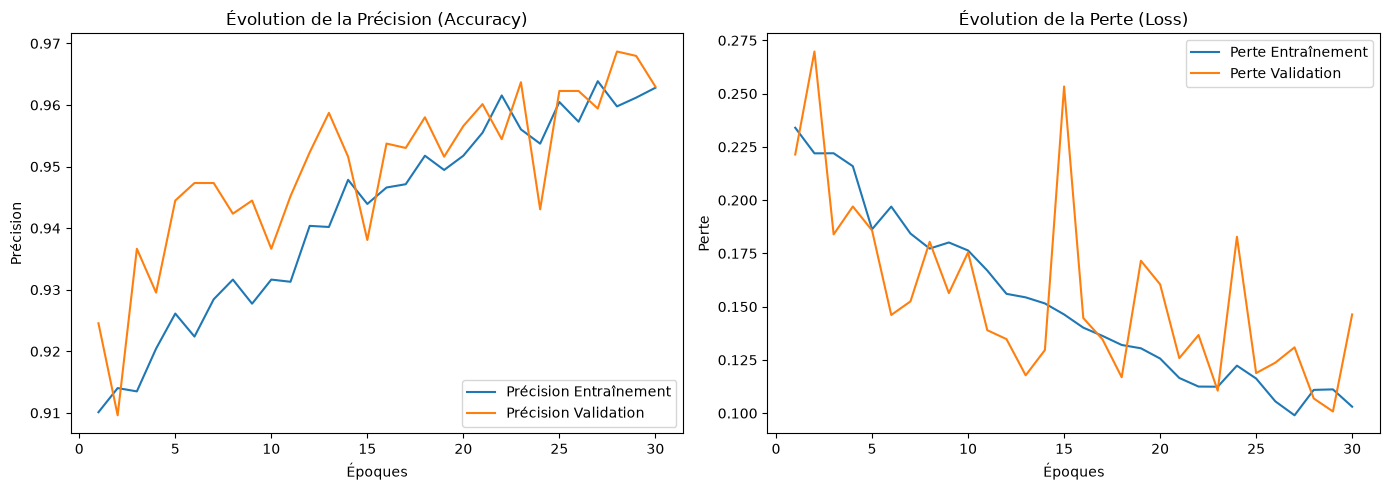

In [67]:
# Récupération de l'historique d'entraînement
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epoches_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# --- Graphique 1 : Précision (Accuracy) ---
plt.subplot(1, 2, 1)
plt.plot(epoches_range, acc, label='Précision Entraînement')
plt.plot(epoches_range, val_acc, label='Précision Validation')
plt.legend(loc='lower right')
plt.title('Évolution de la Précision (Accuracy)')
plt.xlabel('Époques')
plt.ylabel('Précision')

# --- Graphique 2 : Perte (Loss) ---
plt.subplot(1, 2, 2)
plt.plot(epoches_range, loss, label='Perte Entraînement')
plt.plot(epoches_range, val_loss, label='Perte Validation')
plt.legend(loc='upper right')
plt.title('Évolution de la Perte (Loss)')
plt.xlabel('Époques')
plt.ylabel('Perte')

plt.tight_layout()
plt.show()

In [68]:
import tensorflow as tf

# Vérification des GPU disponibles
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print(f"GPU activé et détecté : {gpus[0].name}")
else:
    print("Aucun GPU détecté. L'entraînement utilisera le CPU.")

Aucun GPU détecté. L'entraînement utilisera le CPU.


44/44 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step


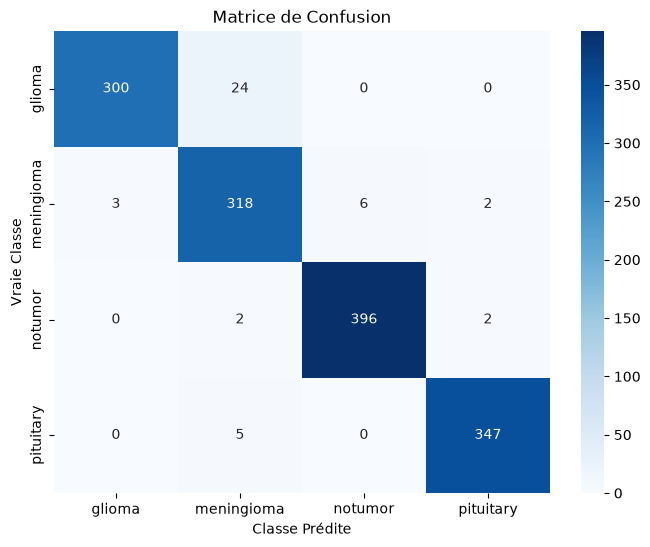

--- Rapport de Classification ---
              precision    recall  f1-score   support

      glioma       0.99      0.93      0.96       324
  meningioma       0.91      0.97      0.94       329
     notumor       0.99      0.99      0.99       400
   pituitary       0.99      0.99      0.99       352

    accuracy                           0.97      1405
   macro avg       0.97      0.97      0.97      1405
weighted avg       0.97      0.97      0.97      1405



In [69]:
# 1. Charger le MEILLEUR modèle sauvegardé
meilleur_modele = load_model('meilleur_modele_brainscan.h5')

# 2. Prédictions sur le jeu de test
y_pred_prob = meilleur_modele.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)        # Indice de la classe prédite
y_true = np.argmax(y_test, axis=1)             # Indice de la vraie classe

# 3. Matrice de confusion
nom_classes = list(le.classes_)
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=nom_classes, yticklabels=nom_classes)
plt.title('Matrice de Confusion')
plt.xlabel('Classe Prédite')
plt.ylabel('Vraie Classe')
plt.show()

# 4. Rapport de classification détaillé
print("--- Rapport de Classification ---")
print(classification_report(y_true, y_pred, target_names=nom_classes))

Nombre de prédictions correctes : 1361
Nombre de prédictions incorrectes : 44


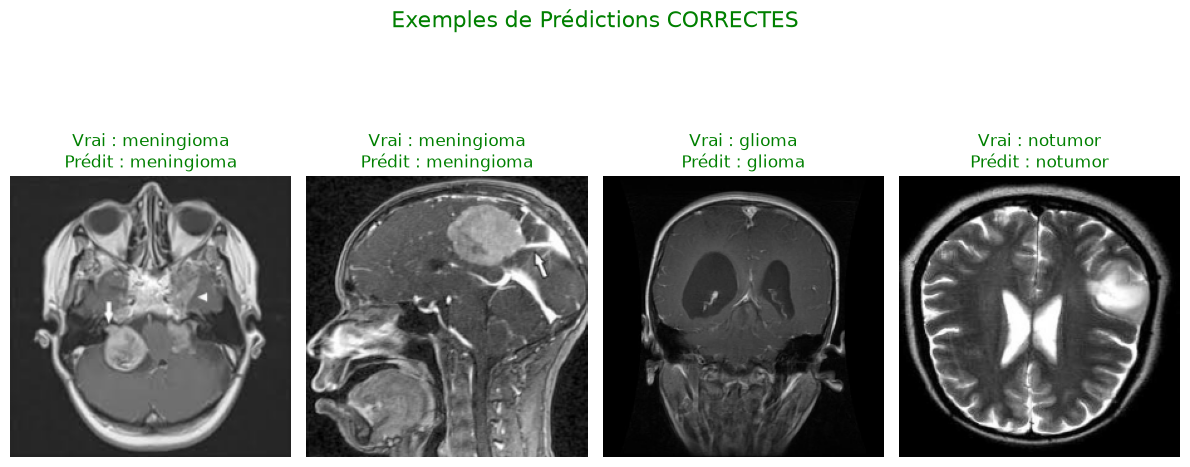

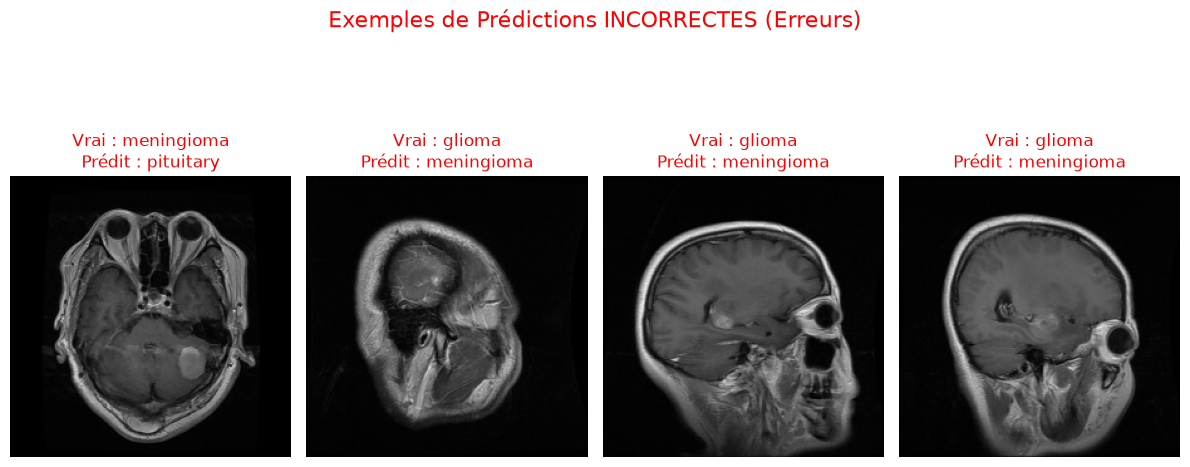

In [70]:
# Identification des indices des prédictions correctes et incorrectes
indices_corrects = np.where(y_pred == y_true)[0]
indices_incorrects = np.where(y_pred != y_true)[0]

print(f"Nombre de prédictions correctes : {len(indices_corrects)}")
print(f"Nombre de prédictions incorrectes : {len(indices_incorrects)}")

# --- 1. Affichage de 4 exemples CORRECTS ---
plt.figure(figsize=(12, 6))
plt.suptitle("Exemples de Prédictions CORRECTES", fontsize=16, color='green')

for i, idx in enumerate(indices_corrects[:4]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(X_test[idx])
    
    classe_vraie = nom_classes[y_true[idx]]
    classe_predite = nom_classes[y_pred[idx]]
    
    plt.title(f"Vrai : {classe_vraie}\nPrédit : {classe_predite}", color='green')
    plt.axis('off')

plt.tight_layout()
plt.show()

# --- 2. Affichage de 4 exemples INCORRECTS ---
plt.figure(figsize=(12, 6))
plt.suptitle("Exemples de Prédictions INCORRECTES (Erreurs)", fontsize=16, color='red')

for i, idx in enumerate(indices_incorrects[:4]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(X_test[idx])
    
    classe_vraie = nom_classes[y_true[idx]]
    classe_predite = nom_classes[y_pred[idx]]
    
    plt.title(f"Vrai : {classe_vraie}\nPrédit : {classe_predite}", color='red')
    plt.axis('off')

plt.tight_layout()
plt.show()